# Day 1-02｜コートの位置をモデルに学習させる：Roboflow のキーポイントアノテーションと YOLO Pose の調整

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day1/d1_02_keypoint_annotation_roboflow_lab_ja.ipynb)

[English](d1_02_keypoint_annotation_roboflow_lab_en.ipynb) | [Japanese](d1_02_keypoint_annotation_roboflow_lab_ja.ipynb) | [Traditional Chinese](d1_02_keypoint_annotation_roboflow_lab.ipynb)


> 前の単元では少数のコートの点を手作業で対応付けた。この単元ではデータセットを作り、新しい画像でもモデルがコートのキーポイントを見つけられるようにする。  
> まずデータ形式を理解し、その後で学習の要否を決める。大型モデルの学習成功だけを演習の成果としない。

## 学習目標

- 画像、アノテーションファイル、`data.yaml` の役割を理解する。
- COCO keypoint 形式を YOLO Pose 形式に変換する理由を説明する。
- 汎用の学習済み重みからの学習と、教材モデルのファインチューニングを区別する。
- 静止画と短い動画で、点の見落とし、位置の誤り、信頼度を確認する。

## 用語

- **データセット（Dataset）**：画像と正解アノテーションの集合。
- **アノテーション（Annotation）**：モデルの学習に使う正解の位置とクラス。
- **Pose model**：順序が決まったキーポイント群を出力するモデル。ここでの pose は人体姿勢ではなくコートの構造を表す。
- **ファインチューニング（Fine-tuning）**：別のデータで学習した重みを追加学習すること。通常はゼロからの学習より時間を抑えられる。


## 実行環境の確認

- Colab では **GPU** ランタイムを選ぶ。本教材の Ultralytics／PyTorch の設定では TPU を直接使用しない。
- CPU でも実行できるが、推論や動画の出力に時間がかかる。最初は `MAX_FRAMES` を小さくして処理を確認する。
- 実行前に各セルの目的を読み、出力が想定どおりか確認する。エラーが出ないことだけで正しいと判断しない。


## データの場所
- Roboflow COCO keypoint export：`assets/datasets/roboflow_court_coco/`
- 変換後の YOLO pose データセット：`assets/datasets/roboflow_court_yolo_pose/`
- 教材のコートキーポイントの重み：`assets/models/court_keypoints/yolo26n_basketball_court_pose_best.pt`
- 学生がアップロードする画像：`assets/student_uploads/roboflow_pose_student_upload_images.zip`
- 実演用の動画：`assets/raw/reference_videos/`

## 操作手順
1. データセットとモデルの重みがあるか確認する。
2. `assets/student_uploads/roboflow_pose_student_upload_images.zip` を展開し、5 枚のコート画像を用意する。
3. Roboflow のサイドバーで `DATA` > `Upload Data` を選び、自分の pose プロジェクトに 5 枚をアップロードする。
4. `DATA` > `Annotate` の `Unassigned` で `Annotate Images` を選び、コートのキーポイントをアノテーションする。
5. プロジェクトの `Versions` で `Generate New Version` / `Publish` を実行する。
6. 新しい `workspace slug`、`project slug`、`version number` をこの Notebook に入力する。
7. 必要に応じて COCO から YOLO Pose に変換する。
8. `TRAIN_MODE` で追加学習の要否と初期化方法を選ぶ。
9. 参照動画からコートのキーポイントを表示した動画を作る。

教材モデルの学習画像は 640x640 の正方形でアノテーションされているため、推論時も画面を正方形に変形してから予測する。

## アップロードする画像
プロジェクトを fork しても、未アノテーションのサンプルが自動で入るとは限らない。`assets/student_uploads/roboflow_pose_student_upload_images.zip` の 5 枚を展開し、次のファイルを自分の Roboflow プロジェクトにアップロードする。

- `boston-celtics-new-york-knicks-game-1-q1-01_54-01_48_mp4-0000.jpg`
- `boston-celtics-new-york-knicks-game-1-q1-01_54-01_48_mp4-0001.jpg`
- `boston-celtics-new-york-knicks-game-1-q1-01_54-01_48_mp4-0002.jpg`
- `boston-celtics-new-york-knicks-game-1-q1-01_54-01_48_mp4-0003.jpg`
- `boston-celtics-new-york-knicks-game-1-q1-01_54-01_48_mp4-0004.jpg`



In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

# 教材フォルダを探し、必要なら取得して共通の環境設定を読み込みます。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


## Roboflow のキーポイント出力形式
`_annotations.coco.json` には `categories[].keypoints`、`categories[].skeleton`、各アノテーションの `keypoints` が必要である。

```text
assets/datasets/roboflow_court_coco/
├── train/
│   ├── _annotations.coco.json
│   └── *.jpg
├── valid/
│   ├── _annotations.coco.json
│   └── *.jpg
└── test/
    ├── _annotations.coco.json
    └── *.jpg
```

変換後のデータは `assets/datasets/roboflow_court_yolo_pose/` に保存する。`data.yaml` には `kpt_shape`、`flip_idx`、`keypoint_names`、`keypoint_skeleton` が含まれる。

Roboflow でアノテーションを修正した場合は、新しいデータセット版を公開してから、次の API ダウンロードを実行する。


In [2]:
# Roboflow のキーポイント出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from src.roboflow_utils import dataset_status
from src.yolo_utils import (
    court_keypoint_model_path,
    preferred_court_keypoint_model_path,
    provided_court_keypoint_model_path,
    tuned_court_keypoint_model_path,
)

COURT_COCO_DIR = COURSE_ROOT / "assets" / "datasets" / "roboflow_court_coco"
COURT_YOLO_POSE_DIR = COURSE_ROOT / "assets" / "datasets" / "roboflow_court_yolo_pose"
COURT_MODEL_PATH = court_keypoint_model_path(COURSE_ROOT)
COURSE_PROVIDED_MODEL_PATH = provided_court_keypoint_model_path(COURSE_ROOT)
TUNED_COURT_MODEL_PATH = tuned_court_keypoint_model_path(COURSE_ROOT)
PREFERRED_COURT_MODEL_PATH = preferred_court_keypoint_model_path(COURSE_ROOT)

print("COCO keypoint export:")
print(dataset_status(COURT_COCO_DIR))
print("\nYOLO pose dataset:")
print(dataset_status(COURT_YOLO_POSE_DIR))
print("\nmodel exists:", COURT_MODEL_PATH.exists(), COURT_MODEL_PATH)
print("provided seed model:", COURSE_PROVIDED_MODEL_PATH)
print("tuned model:", TUNED_COURT_MODEL_PATH.exists(), TUNED_COURT_MODEL_PATH)
print("preferred inference model:", PREFERRED_COURT_MODEL_PATH)


COCO keypoint export:
{'path': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_court_coco', 'exists': True, 'data_yaml': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_court_coco/data.yaml', 'data_yaml_exists': False, 'splits': {}}

YOLO pose dataset:
{'path': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_court_yolo_pose', 'exists': True, 'data_yaml': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/datasets/roboflow_court_yolo_pose/data.yaml', 'data_yaml_exists': False, 'splits': {}}

model exists: True /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/court_keypoints/yolo26n_basketball_court_pose_best.pt
provided seed model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/court_keypoints/yolo26n_basketball_court_pose_best.pt
tuned model: False /Users/henry753951/Developer

In [3]:
# Roboflow のキーポイント出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from getpass import getpass
from src.roboflow_utils import (
    convert_roboflow_coco_keypoints_to_yolo_pose,
    ensure_roboflow_court_pose_dataset,
    find_coco_annotation,
)

# 課題の推奨手順：
# 1. assets/student_uploads/roboflow_pose_student_upload_images.zip を展開します。
# 2. Roboflow の DATA > Upload Data で 5 枚をアップロードします。
# 3. DATA > Annotate の Unassigned で Annotate Images を選び、キーポイントを付けます。
# 4. Versions で Generate New Version / Publish を選びます。
# 5. 新しい workspace / project / version を下に入力します。
# 6. USE_ROBOFLOW_DOWNLOAD を True にします。
USE_ROBOFLOW_DOWNLOAD = False
ROBOFLOW_WORKSPACE = "YOUR_WORKSPACE"
ROBOFLOW_PROJECT = "YOUR_PROJECT"
ROBOFLOW_VERSION = 1
ROBOFLOW_API_KEY = ""
FORCE_DOWNLOAD = False
FORCE_CONVERSION = False

data_yaml = COURT_YOLO_POSE_DIR / "data.yaml"
if USE_ROBOFLOW_DOWNLOAD:
    api_key = ROBOFLOW_API_KEY or getpass("Roboflow API key: ")
    data_yaml = ensure_roboflow_court_pose_dataset(
        coco_dir=COURT_COCO_DIR,
        yolo_pose_dir=COURT_YOLO_POSE_DIR,
        workspace=ROBOFLOW_WORKSPACE,
        project=ROBOFLOW_PROJECT,
        version=ROBOFLOW_VERSION,
        api_key=api_key,
        export_format="coco",
        overwrite_download=FORCE_DOWNLOAD,
        overwrite_conversion=FORCE_CONVERSION,
    )
    print("ready data.yaml:", data_yaml)
elif data_yaml.exists() and not FORCE_CONVERSION:
    print("YOLO pose dataset already exists:", data_yaml)
elif find_coco_annotation(COURT_COCO_DIR / "train") is not None:
    data_yaml = convert_roboflow_coco_keypoints_to_yolo_pose(
        COURT_COCO_DIR,
        COURT_YOLO_POSE_DIR,
        overwrite=FORCE_CONVERSION,
    )
    print("converted data.yaml:", data_yaml)
else:
    print("コートのデータセットがありません。COCO 出力を配置するか、Roboflow の新版を公開して API 設定を入力し、USE_ROBOFLOW_DOWNLOAD=True にしてください。")


コートのデータセットがありません。COCO 出力を配置するか、Roboflow の新版を公開して API 設定を入力し、USE_ROBOFLOW_DOWNLOAD=True にしてください。


In [4]:
# Roboflow のキーポイント出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
TRAIN_MODE = "skip"
# 選択できる設定：
# - "skip"：学習せず、assets/models/ の既存モデルを使います。
# - "base"：yolo26n-pose.pt から学習し、調整後のモデルを別途保存します。
# - "course"：教材の元の重みから追加学習し、調整後のモデルを別途保存します。
# - "resume"：前回の last.pt から再開し、調整後のモデルを別途保存します。

TRAIN_PROJECT_DIR = COURSE_ROOT / "assets" / "results" / "training" / "court_keypoints"
TRAIN_CONFIG = {
    "epochs": 200,
    "imgsz": 960,
    "batch": -1,
    "workers": 8,
    "patience": 50,
    "plots": True,
    "single_cls": True,
    "close_mosaic": 0,
    "hsv_h": 0.01,
    "hsv_s": 0.25,
    "hsv_v": 0.20,
    "degrees": 0.0,
    "translate": 0.03,
    "scale": 0.15,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.0,
    "erasing": 0.0,
    "optimizer": "AdamW",
    "lr0": 0.003,
    "lrf": 0.03,
    "warmup_epochs": 5,
    "cos_lr": True,
}

if TRAIN_MODE in {"base", "course", "resume"}:
    import hashlib

    from ultralytics import YOLO
    from src.yolo_utils import publish_trained_model

    def file_digest(path: Path) -> str:
        digest = hashlib.sha256()
        with Path(path).open("rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                digest.update(chunk)
        return digest.hexdigest()[:12]

    data_yaml = COURT_YOLO_POSE_DIR / "data.yaml"
    if not data_yaml.exists():
        raise FileNotFoundError(
            "YOLO pose の data.yaml がありません。先に COCO から YOLO Pose に変換してください。"
        )

    run_name = (
        "yolo26n_basketball_court_pose_course"
        if TRAIN_MODE in {"course", "resume"}
        else "yolo26n_basketball_court_pose_base"
    )
    planned_save_dir = TRAIN_PROJECT_DIR / run_name
    last_checkpoint = planned_save_dir / "weights" / "last.pt"

    if TRAIN_MODE == "resume":
        if not last_checkpoint.exists():
            raise FileNotFoundError(
                f"再開用の重みがありません：{last_checkpoint}。先に base または course で学習してください。"
            )
        init_weights = last_checkpoint
    elif TRAIN_MODE == "course":
        if not COURSE_PROVIDED_MODEL_PATH.exists():
            raise FileNotFoundError(
                "教材の元のコートキーポイント重みがないため、course の追加学習は利用できません。"
            )
        init_weights = COURSE_PROVIDED_MODEL_PATH
    else:
        init_weights = Path("yolo26n-pose.pt")

    print("TRAIN_MODE:", TRAIN_MODE)
    print("data yaml:", data_yaml)
    print("course model path:", COURT_MODEL_PATH, "exists=", COURT_MODEL_PATH.exists())
    print("course provided seed model:", COURSE_PROVIDED_MODEL_PATH, "exists=", COURSE_PROVIDED_MODEL_PATH.exists())
    print("tuned model path:", TUNED_COURT_MODEL_PATH, "exists=", TUNED_COURT_MODEL_PATH.exists())
    print("last checkpoint:", last_checkpoint, "exists=", last_checkpoint.exists())
    print("selected init weights:", init_weights)
    print("planned run dir:", planned_save_dir)
    print("planned published model path:", TUNED_COURT_MODEL_PATH)
    if init_weights.exists():
        print("selected init weights bytes:", init_weights.stat().st_size)
        print("selected init weights sha256[:12]:", file_digest(init_weights))
    else:
        print("selected init weights is not a local file yet; Ultralytics may download it on demand.")

    model = YOLO(str(init_weights))
    train_kwargs = {
        "data": str(data_yaml),
        "project": str(TRAIN_PROJECT_DIR),
        "name": run_name,
        "exist_ok": TRAIN_MODE == "resume",
        "resume": TRAIN_MODE == "resume",
        **TRAIN_CONFIG,
    }
    print("train kwargs:", train_kwargs)
    results = model.train(**train_kwargs)
    save_dir = Path(getattr(getattr(model, "trainer", None), "save_dir", getattr(results, "save_dir", "")))
    trained_best = save_dir / "weights" / "best.pt"
    published_model_path = publish_trained_model(trained_best, TUNED_COURT_MODEL_PATH)

    print("init weights:", init_weights)
    print("run dir:", save_dir)
    print("trained best exists:", trained_best.exists(), trained_best)
    if trained_best.exists():
        print("trained best sha256[:12]:", file_digest(trained_best))
    print("published tuned model:", published_model_path)
    if published_model_path.exists():
        print("published tuned model sha256[:12]:", file_digest(published_model_path))
else:
    print("TRAIN_MODE=skip：assets/models/court_keypoints/ のモデルを使います。")


TRAIN_MODE=skip：assets/models/court_keypoints/ のモデルを使います。


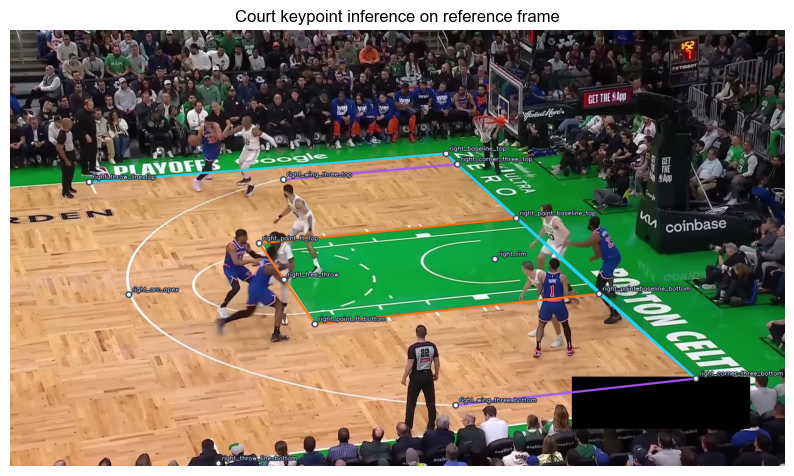

video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
keypoint count: 14
homography estimated: True
saved frame preview: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_02_court_keypoints.png


$ /opt/homebrew/bin/ffmpeg -y -i /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_02_court_pose_demo.mp4 -an -vcodec libx264 -pix_fmt yuv420p -movflags +faststart -preset veryfast -crf 23 /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_02_court_pose_demo.notebook.mp4


saved video demo: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_02_court_pose_demo.mp4
saved json: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d1_02_court_pose_demo.json
frames: 120


In [5]:
# Roboflow のキーポイント出力形式を確認します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO
from src.video_utils import display_video_in_notebook

from src.cv_utils import save_json, save_image_rgb, show_image
from src.geometry_utils import render_bev_court
from src.yolo_utils import (
    bev_court_bounds,
    court_keypoints_from_result,
    draw_court_keypoint_records,
    predict_court_pose_result,
    write_court_keypoint_preview_video,
)

BEV_SPEC_PATH = COURSE_ROOT / "assets" / "samples" / "sample_bev_court.json"
INFERENCE_MODEL_PATH = preferred_court_keypoint_model_path(COURSE_ROOT)
video_candidates = sorted((COURSE_ROOT / "assets" / "raw" / "reference_videos").glob("*.mp4"))
if not video_candidates:
    raise FileNotFoundError("参照動画がありません。assets/raw/reference_videos/ に mp4 を 1 本以上配置してください。")
video_path = video_candidates[0]

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise FileNotFoundError(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 60)
ok, frame_bgr = cap.read()
cap.release()
if not ok:
    raise RuntimeError(f"フレーム 60 を読めません：{video_path}")
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
bev = render_bev_court(BEV_SPEC_PATH)

model = YOLO(str(INFERENCE_MODEL_PATH))
result = predict_court_pose_result(model, frame, conf=0.15, imgsz=960)
keypoints = court_keypoints_from_result(
    result,
    bev.shape,
    frame_index=60,
    anchor_confidence=0.25,
    court_bounds=bev_court_bounds(BEV_SPEC_PATH),
)

src = np.asarray([kp.image_xy for kp in keypoints], dtype=np.float32)
dst = np.asarray([kp.bev_xy for kp in keypoints], dtype=np.float32)
H = None
if len(src) >= 6:
    H, mask = cv2.findHomography(src, dst, method=cv2.RANSAC, ransacReprojThreshold=5.0)
    if H is not None and mask is not None and int(mask.ravel().sum()) < 6:
        H = None

frame_vis = draw_court_keypoint_records(frame, keypoints)
show_image(frame_vis, "Court keypoint inference on reference frame")

out_image = COURSE_ROOT / "assets" / "results" / "d1_02_court_keypoints.png"
out_json = COURSE_ROOT / "assets" / "results" / "d1_02_court_keypoints.json"
save_image_rgb(out_image, frame_vis)
save_json([record.__dict__ for record in keypoints], out_json)

print("video:", video_path)
print("keypoint count:", len(keypoints))
print("homography estimated:", H is not None)
print("saved frame preview:", out_image)
pd.DataFrame([record.__dict__ for record in keypoints]).head()

preview_video_path = COURSE_ROOT / "assets" / "results" / "d1_02_court_pose_demo.mp4"
preview_video_path, preview_rows = write_court_keypoint_preview_video(
    video_path=video_path,
    model_path=INFERENCE_MODEL_PATH,
    bev_spec_path=BEV_SPEC_PATH,
    output_path=preview_video_path,
    max_frames=120,
    conf=0.15,
    anchor_confidence=0.25,
    imgsz=960,
    start_frame=40,
)
preview_json = preview_video_path.with_suffix('.json')

print("saved video demo:", preview_video_path)
print("saved json:", preview_json)
print("frames:", len(preview_rows))
display_video_in_notebook(preview_video_path, loop=True)


## 出力ファイル

- `assets/datasets/roboflow_court_coco/`：手作業で配置、または API で取得した COCO keypoint データ。
- `assets/datasets/roboflow_court_yolo_pose/data.yaml` と対応する images／labels：変換後の YOLO pose データセット。
- `assets/results/d1_02_court_keypoints.png`：1 フレームのコートキーポイント確認図。
- `assets/results/d1_02_court_keypoints.json`：1 フレームのキーポイント予測。
- `assets/results/d1_02_court_pose_demo.mp4`：コートキーポイントの確認動画。
- `assets/results/d1_02_court_pose_demo.json`：動画のフレームごとの概要。
- `TRAIN_MODE != "skip"` の場合は、Ultralytics の学習出力フォルダも作成される。
- `TRAIN_MODE != "skip"` で学習に成功すると、調整後のモデルを `assets/models/court_keypoints/yolo26n_basketball_court_pose_tuned.pt` に保存する。元の `yolo26n_basketball_court_pose_best.pt` は保持される。
